In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [6]:
df= pd.read_csv(r"C:\Users\DELL\Downloads\Housing_data.csv")
df

,Price,LivingArea,Bathrooms,Bedrooms,LotSize,Age,Fireplace
0,16858,1629,1.0,3,0.76,180,0
1,26049,1344,2.0,3,0.92,13,0
2,26130,822,1.0,2,0.56,173,0
3,31113,1540,1.0,2,0.04,115,0
4,40932,1320,1.0,3,0.17,90,0
...,...,...,...,...,...,...,...
1042,387652,3504,2.5,5,0.90,0,1
1043,391842,3003,3.5,4,0.46,88,1
1044,394532,3361,3.5,4,0.71,1,1
1045,432845,3250,2.5,3,0.53,23,1


In [7]:
df.shape

(1047, 7)

In [8]:
df.head()

,Price,LivingArea,Bathrooms,Bedrooms,LotSize,Age,Fireplace
0,16858,1629,1.0,3,0.76,180,0
1,26049,1344,2.0,3,0.92,13,0
2,26130,822,1.0,2,0.56,173,0
3,31113,1540,1.0,2,0.04,115,0
4,40932,1320,1.0,3,0.17,90,0


In [9]:
#### info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Price       1047 non-null   int64  
 1   LivingArea  1047 non-null   int64  
 2   Bathrooms   1047 non-null   float64
 3   Bedrooms    1047 non-null   int64  
 4   LotSize     1047 non-null   float64
 5   Age         1047 non-null   int64  
 6   Fireplace   1047 non-null   int64  
dtypes: float64(2), int64(5)
memory usage: 57.4 KB


In [10]:
### duplicates
df.duplicated().sum()

np.int64(12)

In [11]:
df.drop_duplicates(inplace=True,ignore_index=True)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
#### Misssing values
df.isnull().sum()

Price         0
LivingArea    0
Bathrooms     0
Bedrooms      0
LotSize       0
Age           0
Fireplace     0
dtype: int64

In [14]:
#### outlier check
target= df[['Price']]
features= df.drop(columns=['Price'])
features.head()

,LivingArea,Bathrooms,Bedrooms,LotSize,Age,Fireplace
0,1629,1.0,3,0.76,180,0
1,1344,2.0,3,0.92,13,0
2,822,1.0,2,0.56,173,0
3,1540,1.0,2,0.04,115,0
4,1320,1.0,3,0.17,90,0


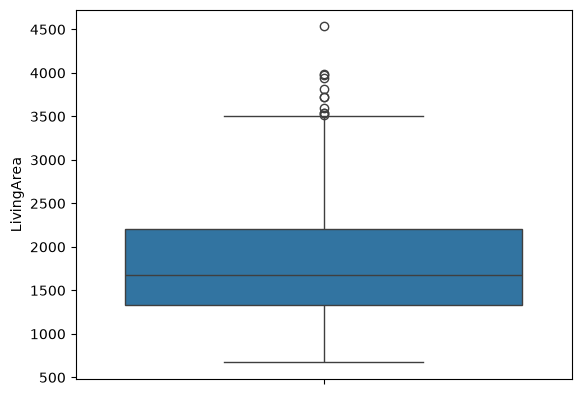

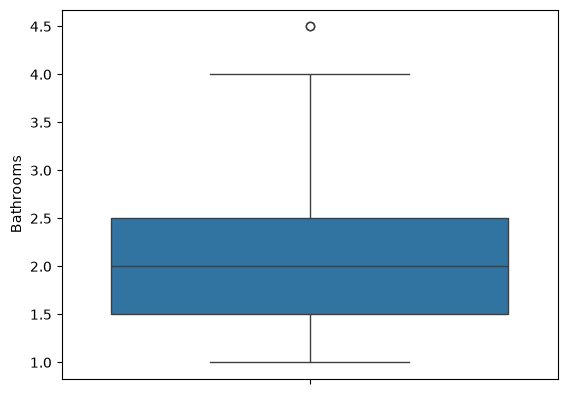

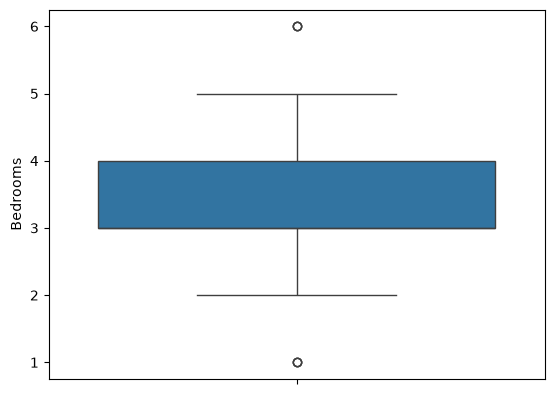

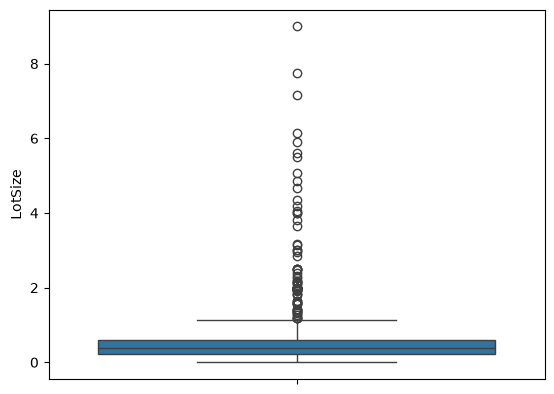

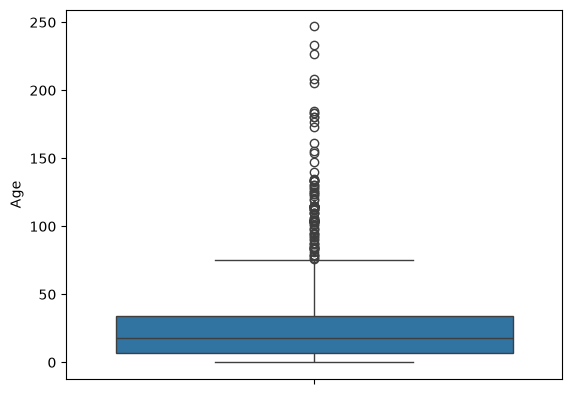

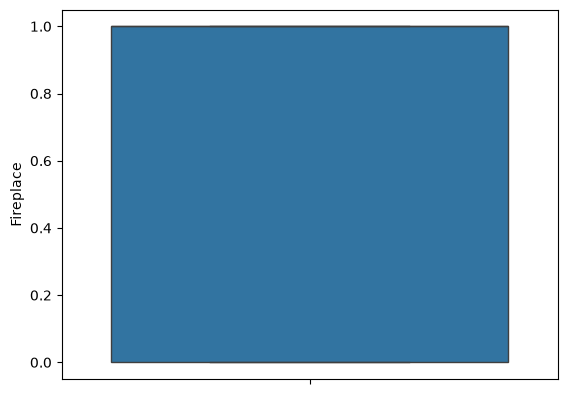

In [15]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

In [16]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

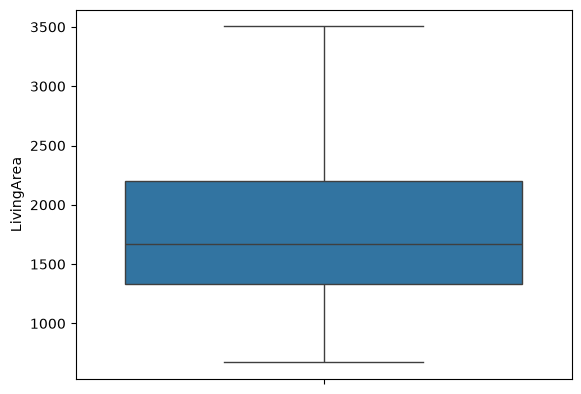

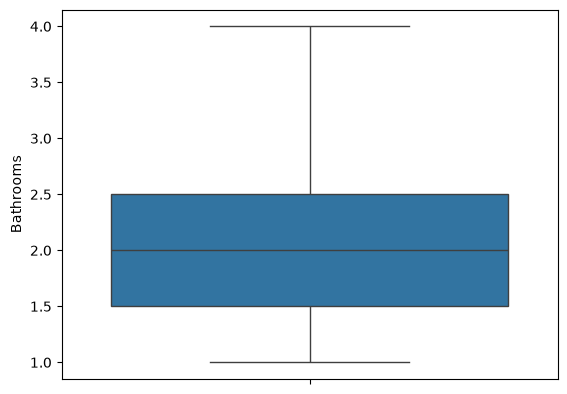

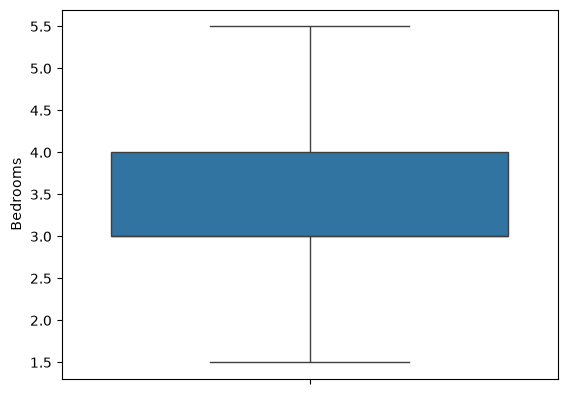

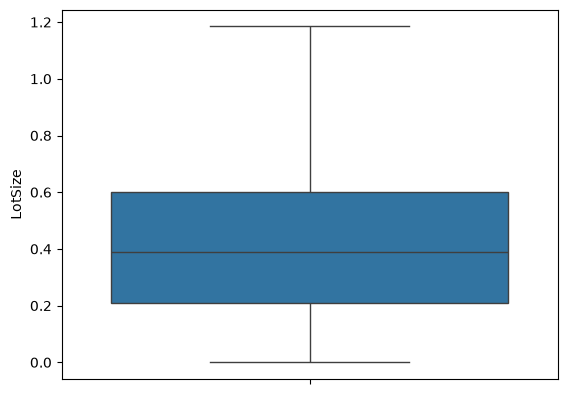

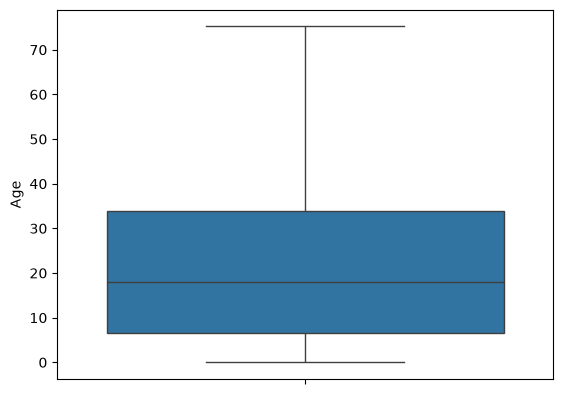

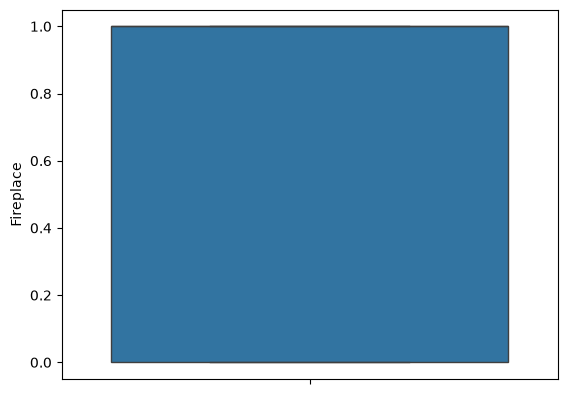

In [17]:
for col in features.columns:
    sns.boxplot(data=features,y=col)
    plt.show()

In [18]:
df1= pd.concat([features,target],axis=1)
df1.head()

,LivingArea,Bathrooms,Bedrooms,LotSize,Age,Fireplace,Price
0,1629.0,1.0,3.0,0.76,75.25,0,16858
1,1344.0,2.0,3.0,0.92,13.00,0,26049
2,822.0,1.0,2.0,0.56,75.25,0,26130
3,1540.0,1.0,2.0,0.04,75.25,0,31113
4,1320.0,1.0,3.0,0.17,75.25,0,40932


<Axes: >

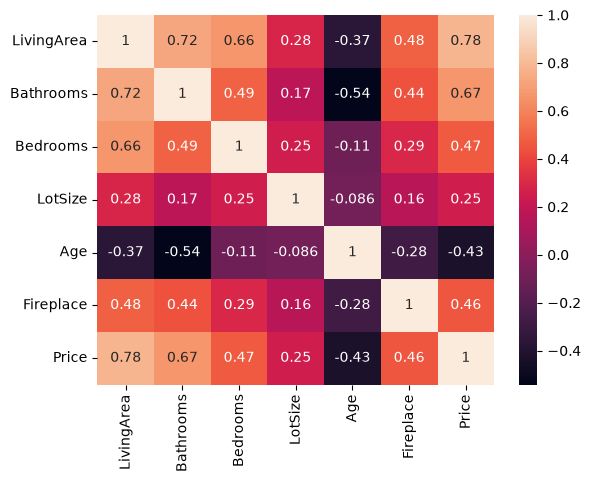

In [19]:
#### correlation
corr=df1.corr()
sns.heatmap(corr,annot=True)

In [20]:
from sklearn.feature_selection import f_regression

<Axes: >

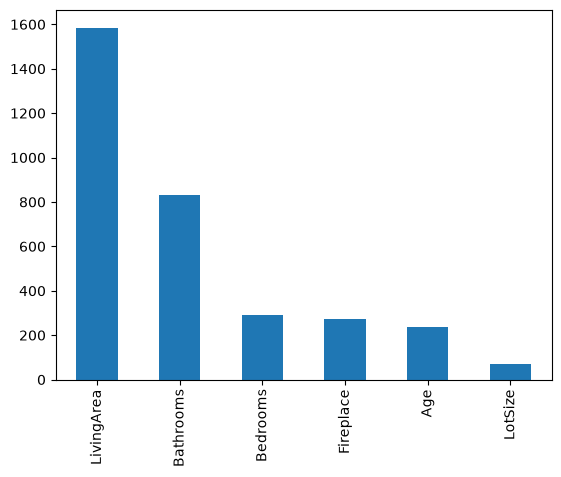

In [21]:
f_reg=f_regression(features,target)
pd.Series(f_reg[0],index=features.columns).sort_values(ascending=False).plot(kind='bar')

In [22]:
features.columns

Index(['LivingArea', 'Bathrooms', 'Bedrooms', 'LotSize', 'Age', 'Fireplace'], dtype='str')

In [24]:
####  Check Multicolinearity
#### Variance Inflation Factor ( VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [25]:
features.head()

,LivingArea,Bathrooms,Bedrooms,LotSize,Age,Fireplace
0,1629.0,1.0,3.0,0.76,75.25,0
1,1344.0,2.0,3.0,0.92,13.00,0
2,822.0,1.0,2.0,0.56,75.25,0
3,1540.0,1.0,2.0,0.04,75.25,0
4,1320.0,1.0,3.0,0.17,75.25,0


In [26]:
features.values

array([[1.629e+03, 1.000e+00, 3.000e+00, 7.600e-01, 7.525e+01, 0.000e+00],
       [1.344e+03, 2.000e+00, 3.000e+00, 9.200e-01, 1.300e+01, 0.000e+00],
       [8.220e+02, 1.000e+00, 2.000e+00, 5.600e-01, 7.525e+01, 0.000e+00],
       ...,
       [3.361e+03, 3.500e+00, 4.000e+00, 7.100e-01, 1.000e+00, 1.000e+00],
       [3.250e+03, 2.500e+00, 3.000e+00, 5.300e-01, 2.300e+01, 1.000e+00],
       [3.467e+03, 2.500e+00, 4.000e+00, 3.400e-01, 3.000e+00, 1.000e+00]],
      shape=(1035, 6))

In [27]:
features.columns

Index(['LivingArea', 'Bathrooms', 'Bedrooms', 'LotSize', 'Age', 'Fireplace'], dtype='str')

In [28]:
for i in range(len(features.columns)):
    print(i)

0
1
2
3
4
5


In [29]:
vif= pd.DataFrame()
vif['Features']= features.columns
vif['VIF_Scores']= [variance_inflation_factor(features.values,i) for i in range(len(features.columns))]

In [30]:
vif

,Features,VIF_Scores
0,LivingArea,28.393716
1,Bathrooms,21.617158
2,Bedrooms,29.100456
3,LotSize,3.345417
4,Age,2.471556
5,Fireplace,3.304989
